Customer churn prediction project

The aim of this project is to analyze customer behavior using the retail customer churn dataset to identify factors contributing to customer churn and develop strategies for improving customer retention.

Specific objectives
1.	To identify key factors influencing customer churn
2.	To develop a prediction model that will predict which customers are more likely to churn
3.	To provide recommendations that will increase retention strategies and reduce churn risk


Research questions
i.	What factors contribute to customer churn in retail businesses?
ii.	Which customers are most likely to churn?
iii. What behavioral patterns lead to churn?
iv.	Which predictive models can accurately predict customers who are likely to churn?
v.	How can the business improve retention strategies?


In [25]:
#import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.pipeline import Pipeline
from sklearn.metrics import (confusion_matrix, classification_report, roc_auc_score,roc_curve, precision_recall_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_score

import joblib
import warnings
warnings.filterwarnings('ignore')

In [3]:
#load the dataset
churn_data = pd.read_csv("C:/Users/eliza/OneDrive - United States International University (USIU)/DATA SETS - DATA SCIENCE/retail_customer_churn_100k (1).csv")

In [4]:
# data inspection


print("The first 5 rows and columns:")
print(churn_data.head())

print("Dataset info:")
print(churn_data.info())

print("Data summary:")
print(churn_data.describe())

print("Missing values count:")
print(churn_data.isnull().sum())  #no missing values

The first 5 rows and columns:
  customer_id age_group gender region customer_segment preferred_channel  \
0     C000001     18-24  Other  North            Loyal            Online   
1     C000002     25-34  Other  South              New        Mobile App   
2     C000003       55+  Other  North              VIP            Online   
3     C000004     18-24   Male  North        Returning        Mobile App   
4     C000005       55+  Other  North        Returning        Mobile App   

   purchase_frequency  avg_order_value  total_spent  recency_days  \
0                   5           381.27      2108.80           189   
1                  12           376.65      3843.06           277   
2                   5            37.73       224.65           271   
3                  12           191.19      1960.79            89   
4                   2           279.64       594.79           264   

   website_visits  discount_usage_rate  email_open_rate  \
0              27                 0.38 

In [5]:
#feature engineering

#convert he churn_risk variable to be categorical
churn_data['churn_risk'] = pd.Categorical(churn_data['churn_risk'], categories=['Low', 'Medium', 'High'], ordered=True)

Exploratory data analysis

1. Univariate analysis to analyse the distribution of individual variables
2. Bivariate analysis
3. Multivariate analysis
4. Correlation
5. Feature importance

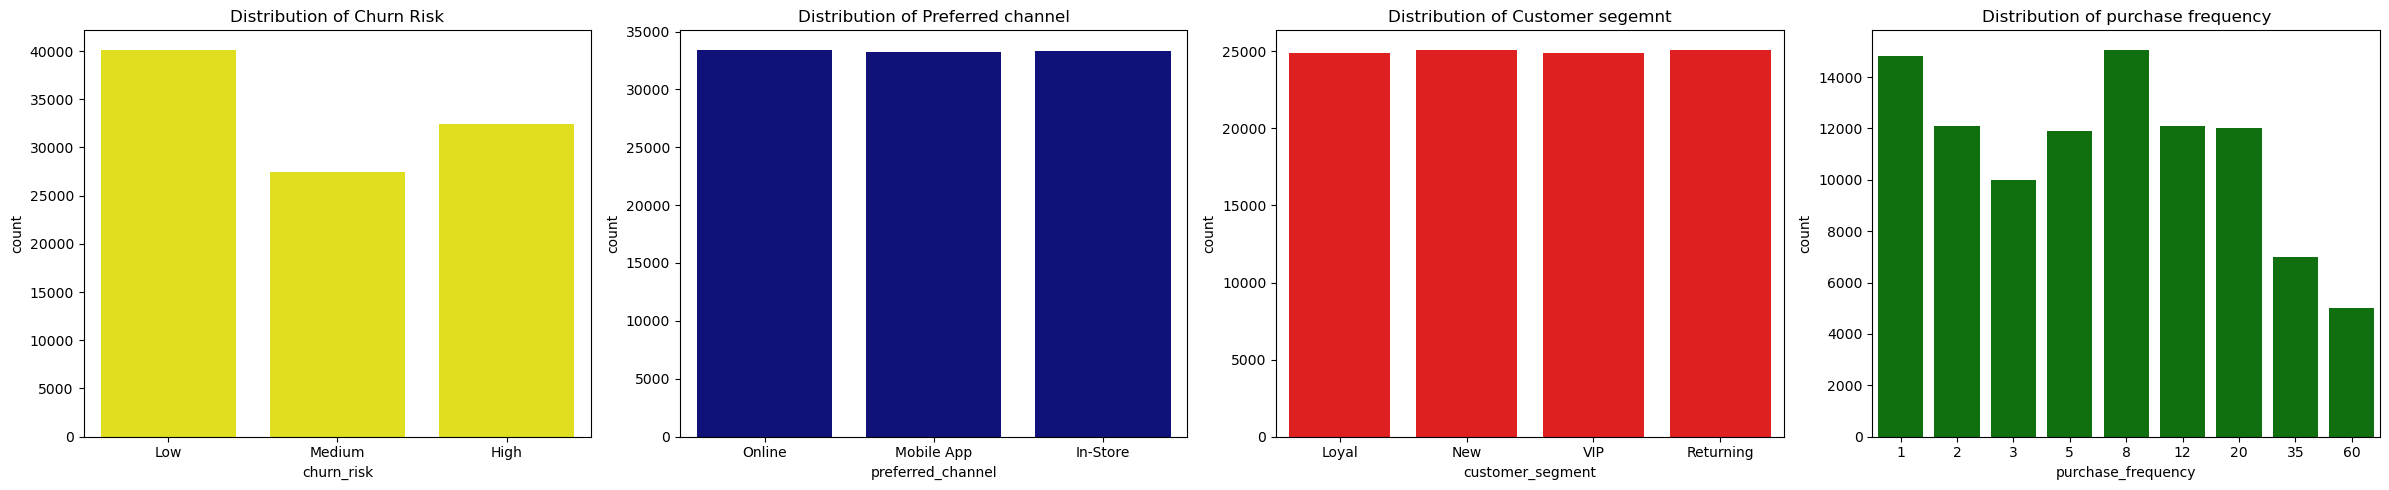

In [41]:
#univariate analysis
fig, axes = plt.subplots(1, 4, figsize=(24, 5))

# Churn risk distribution (Target variable)
sns.countplot(data=churn_data, x='churn_risk', ax=axes[0], color='yellow')
axes[0].set_title('Distribution of Churn Risk')

# Preferred_channel distribution
sns.countplot(data=churn_data, x='preferred_channel', ax=axes[1], color='darkblue')
axes[1].set_title('Distribution of Preferred channel')

#customer_segement distribution
sns.countplot(data=churn_data, x='customer_segment', ax=axes[2], color='red')
axes[2].set_title('Distribution of Customer segemnt')

#purchase frequency
sns.countplot(data=churn_data, x='purchase_frequency', ax=axes[3], color='green')
axes[3].set_title('Distribution of purchase frequency')

plt.tight_layout()
plt.show()

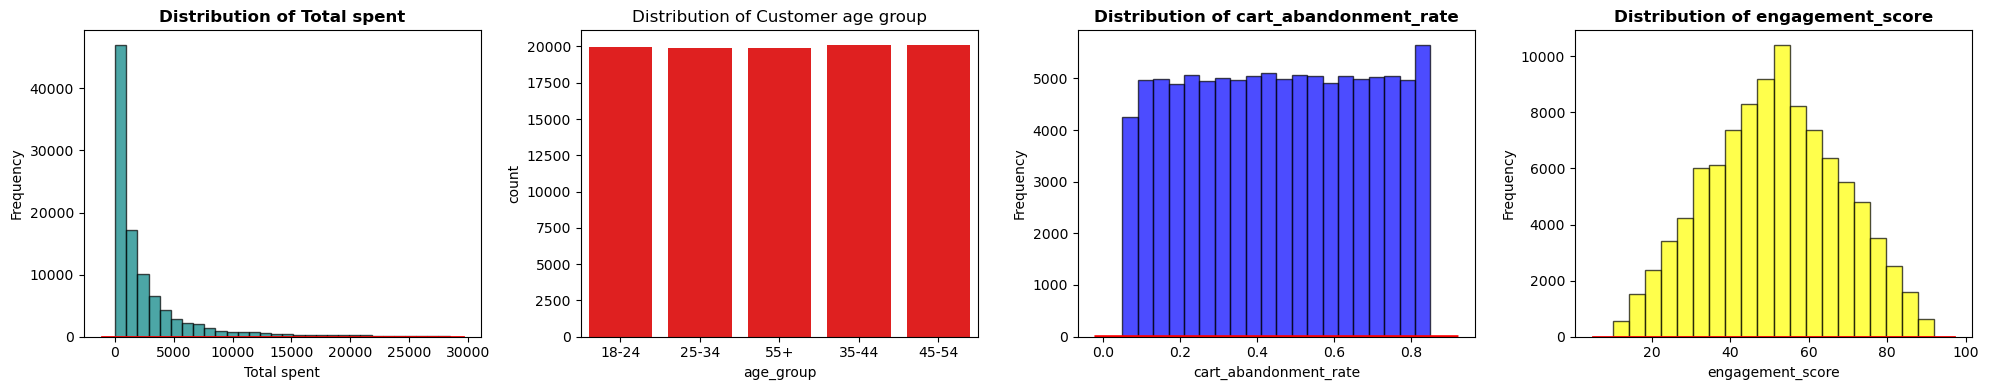

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

#total spent
axes[0].hist(churn_data['total_spent'], bins=30, color='teal', alpha=0.7, edgecolor='black')
axes[0].set_title('Distribution of Total spent', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Total spent')
axes[0].set_ylabel('Frequency')
sns.kdeplot(churn_data['total_spent'], ax=axes[0], color='red', linewidth=2)

#age group
sns.countplot(data=churn_data, x='age_group', ax=axes[1], color='red')
axes[1].set_title('Distribution of Customer age group')

#cart abandonment rate
axes[2].hist(churn_data['cart_abandonment_rate'], bins=20, color='blue', alpha=0.7, edgecolor='black')
axes[2].set_title('Distribution of cart_abandonment_rate', fontsize=12, fontweight='bold')
axes[2].set_xlabel('cart_abandonment_rate')
axes[2].set_ylabel('Frequency')
sns.kdeplot(churn_data['cart_abandonment_rate'], ax=axes[2], color='red', linewidth=2)

#engagement_score
axes[3].hist(churn_data['engagement_score'], bins=20, color='yellow', alpha=0.7, edgecolor='black')
axes[3].set_title('Distribution of engagement_score', fontsize=12, fontweight='bold')
axes[3].set_xlabel('engagement_score')
axes[3].set_ylabel('Frequency')
sns.kdeplot(churn_data['engagement_score'], ax=axes[3], color='red', linewidth=2)

plt.tight_layout()
plt.show()


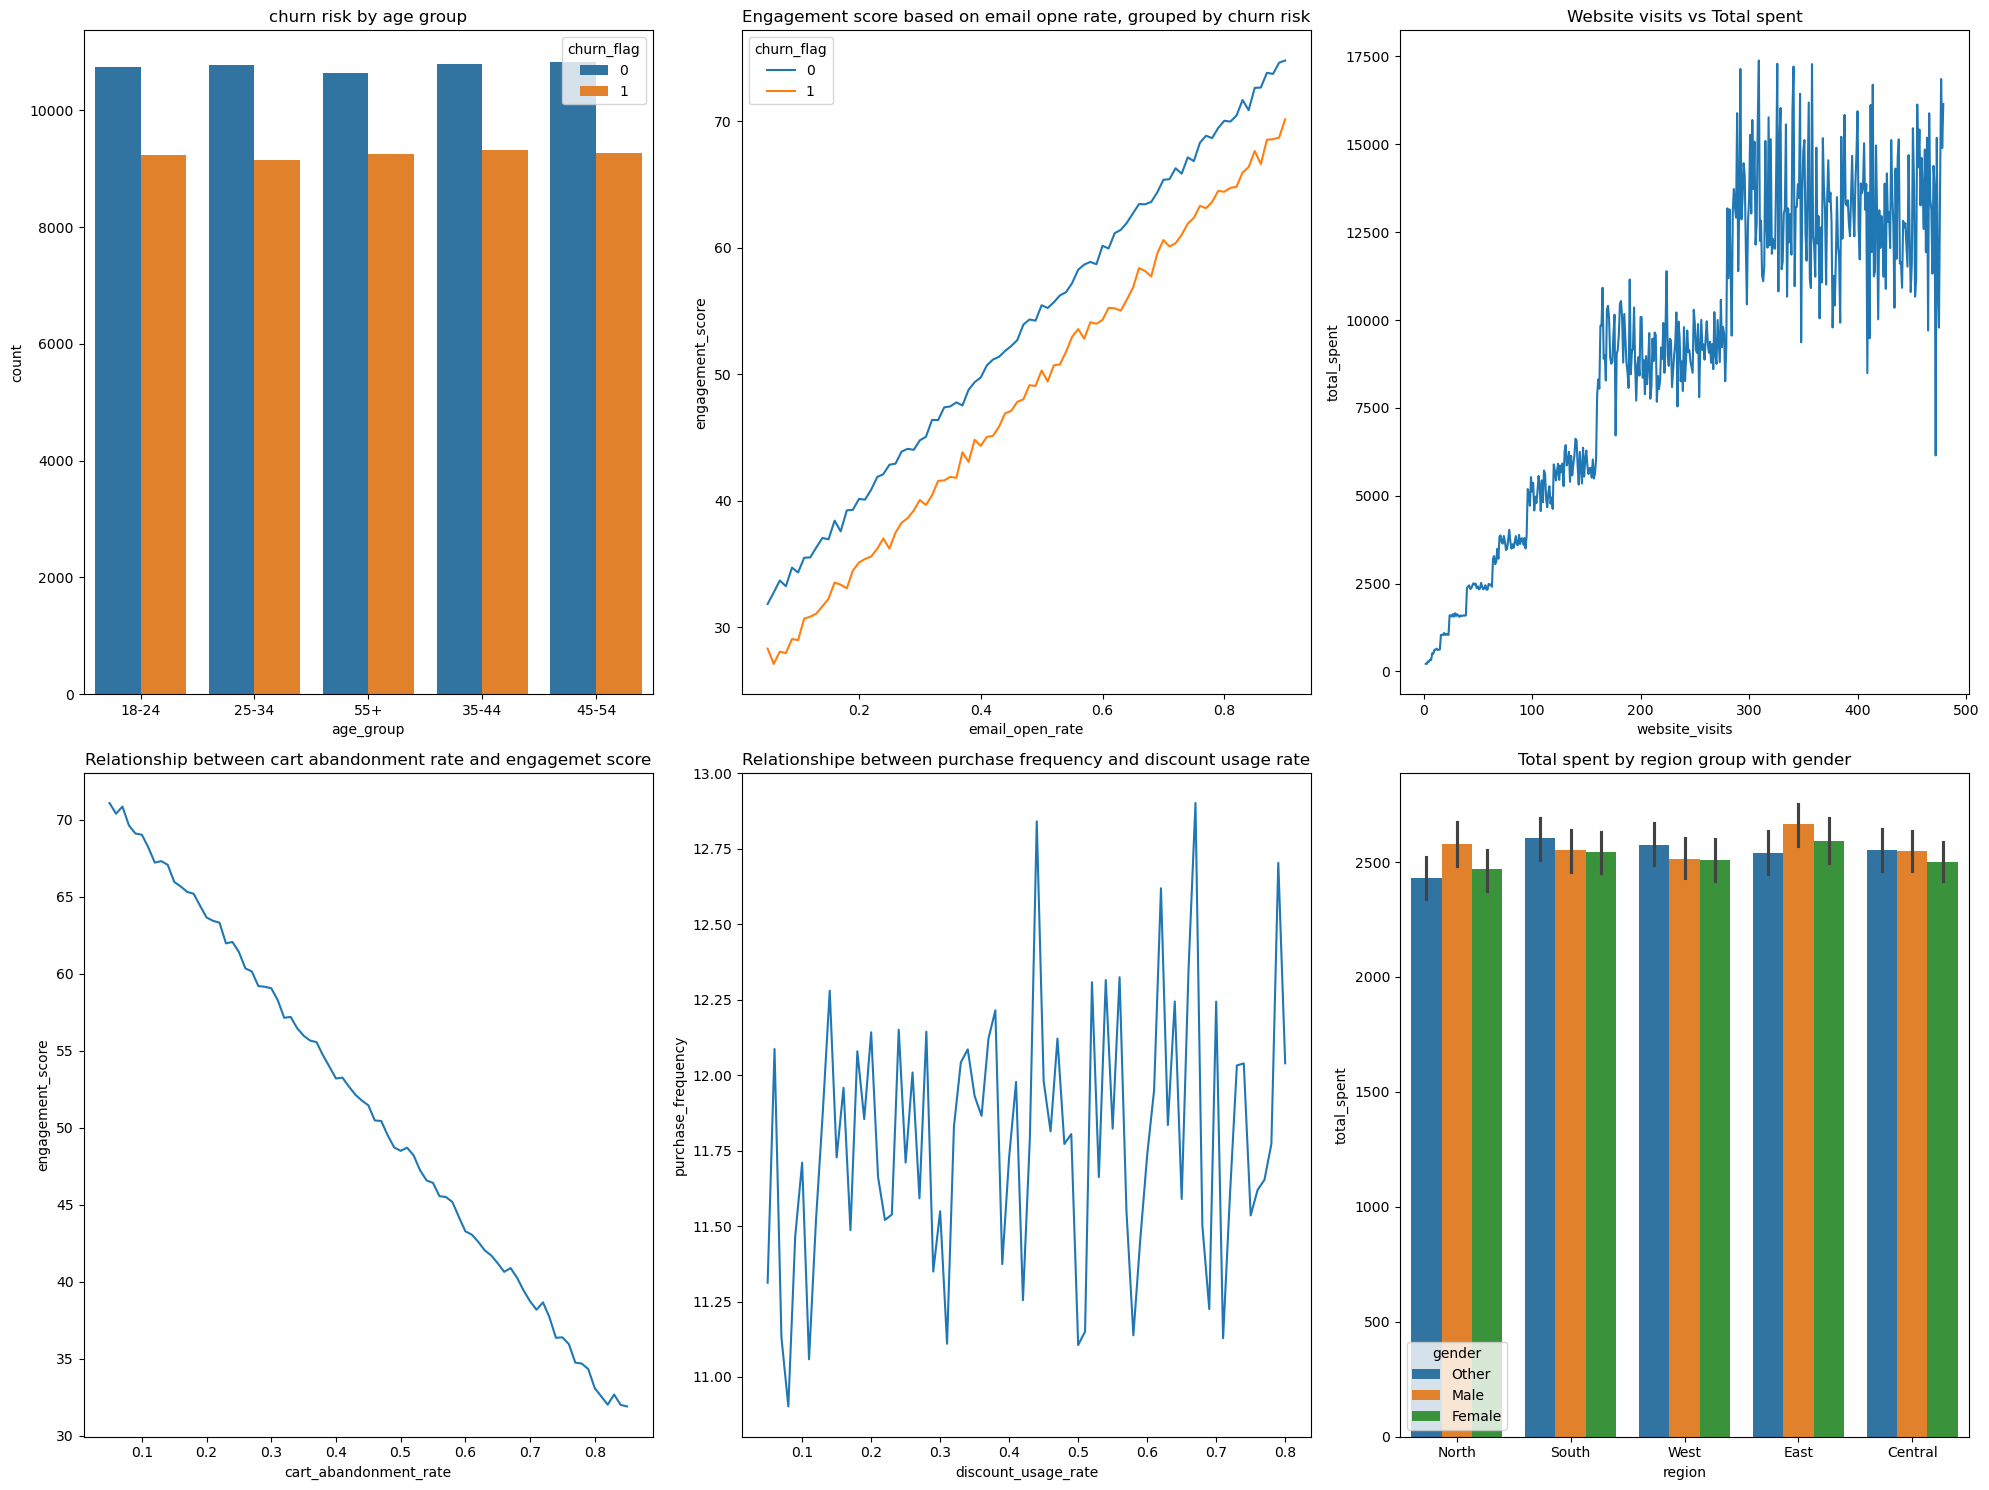

In [43]:
#binomial distributions
fig, axes = plt.subplots(2,3 , figsize = (20, 15))
axes = axes.ravel()

#1. churn risk by age group
sns.countplot(data=churn_data, x='age_group', ax=axes[0], hue = 'churn_flag')
axes[0].set_title('churn risk by age group')

#2. email open rate vs engament score based on churn risk
sns.lineplot(x = churn_data['email_open_rate'], y = churn_data['engagement_score'], ax = axes[1], ci = None, hue = churn_data['churn_flag'])
axes[1].set_title('Engagement score based on email opne rate, grouped by churn risk')


#3. website visits vs total spent
sns.lineplot(x = churn_data['website_visits'], y = churn_data['total_spent'], ax = axes[2], ci = None)
axes[2].set_title('Website visits vs Total spent')

#4. cart abandonment rate vs engagement score
sns.lineplot(x = churn_data['cart_abandonment_rate'], y = churn_data['engagement_score'], ax = axes[3], ci = None)
axes[3].set_title('Relationship between cart abandonment rate and engagemet score')

#5. purchase frequency vs discount usage rate
sns.lineplot(x = churn_data['discount_usage_rate'], y = churn_data['purchase_frequency'], ax = axes[4], ci = None)
axes[4].set_title('Relationshipe between purchase frequency and discount usage rate')

#6. total spent vs region grouped by gender
sns.barplot(x = churn_data['region'], y = churn_data['total_spent'], ax=axes[5], hue = churn_data['gender'])
axes[5].set_title('Total spent by region group with gender')

plt.tight_layout()
plt.show()

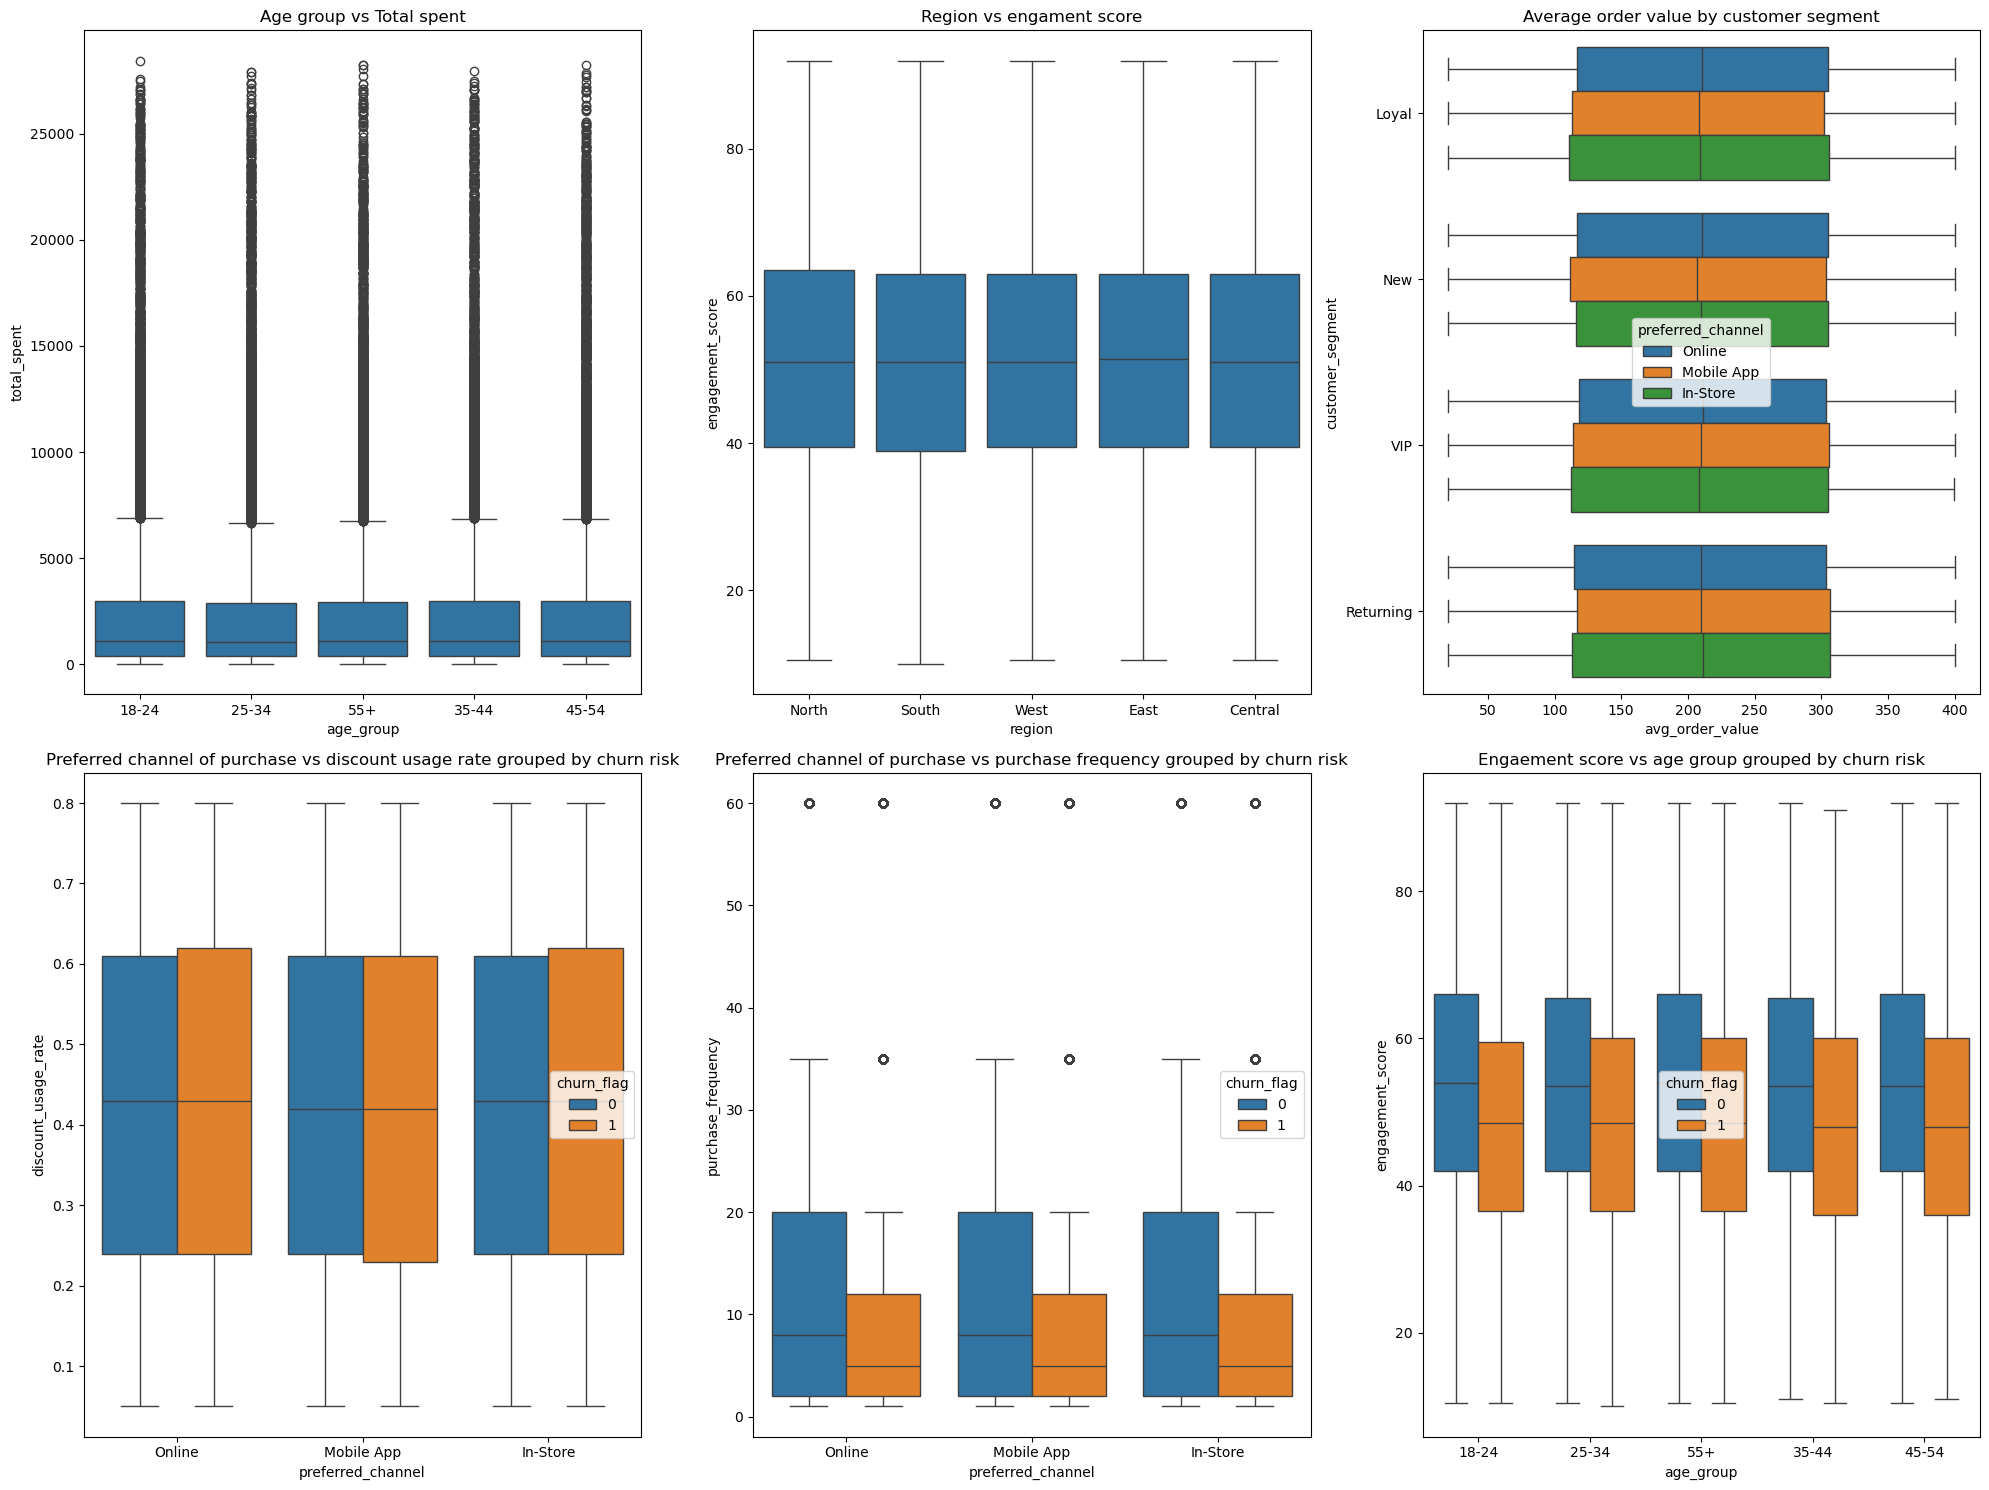

In [10]:
fig, axes = plt.subplots(2,3 , figsize = (20, 15))
axes = axes.ravel()

# age group vs total spent
sns.boxplot(data = churn_data, x = 'age_group', y = 'total_spent', ax = axes[0])
axes[0].set_title('Age group vs Total spent')

# engagement score vs region
sns.boxplot(data = churn_data, x = 'region', y = 'engagement_score', ax = axes[1])
axes[1].set_title('Region vs engament score')

#Average order value by customer segment
sns.boxplot(data = churn_data, x = 'avg_order_value', y = 'customer_segment', ax = axes[2], hue = 'preferred_channel')
axes[2].set_title('Average order value by customer segment')

#customer churn risk vs preferred channel vs discount usage rate
sns.boxplot(data = churn_data, x = 'preferred_channel', y = 'discount_usage_rate', ax = axes[3], hue = 'churn_flag')
axes[3].set_title('Preferred channel of purchase vs discount usage rate grouped by churn risk')

#purchase frequency vs preferred channel
sns.boxplot(data = churn_data, x = 'preferred_channel', y = 'purchase_frequency', ax = axes[4], hue = 'churn_flag')
axes[4].set_title('Preferred channel of purchase vs purchase frequency grouped by churn risk')

#engagement score vs age group
sns.boxplot(data = churn_data, x = 'age_group', y = 'engagement_score', ax = axes[5], hue = 'churn_flag')
axes[5].set_title('Engaement score vs age group grouped by churn risk')


plt.tight_layout()
plt.show()


In [53]:
#correlation

numeric_cols = ["purchase_frequency", "avg_order_value", "total_spent", "recency_days",
                 "website_visits", "discount_usage_rate", "email_open_rate",
                 "cart_abandonment_rate", "loyalty_score"]

categorical_cols = ["age_group", "gender", "region", "customer_segment", "preferred_channel"]



In [59]:
corr = churn_data[numeric_cols + ["churn_flag"]].corr()
print(corr["churn_flag"])


purchase_frequency      -0.049854
avg_order_value         -0.004330
total_spent             -0.042300
recency_days             0.774030
website_visits          -0.044094
discount_usage_rate      0.001864
email_open_rate          0.002463
cart_abandonment_rate    0.228116
loyalty_score           -0.175249
churn_flag               1.000000
Name: churn_flag, dtype: float64


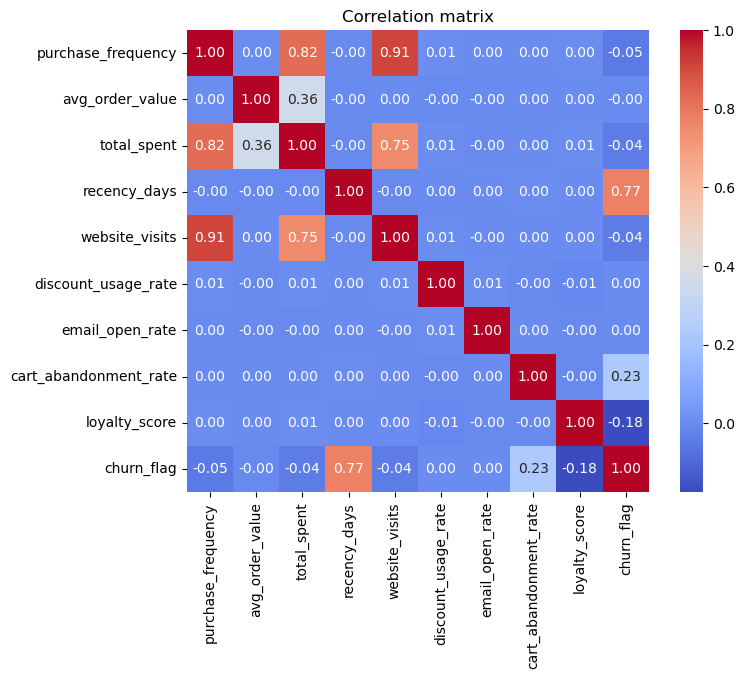

<Figure size 640x480 with 0 Axes>

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Correlation matrix")
plt.show()
plt.tight_layout()


## 4. Data Preprocessing

**Data Preprocessing Steps:**
1. **Categorical Encoding**: Convert categorical columns (sex, region, smoker) to numeric using one-hot encoding
2. **Feature-Target Separation**: Separate features (X) from target (y)
3. **Integer Conversion**: Convert encoded features to integer type for cleaner data
4. **Train/Test Split**: Split data into training (85%) and testing (25%) sets with random_state for reproducibility
5. **Feature Scaling**: Apply StandardScaler AFTER train/test split to prevent data leakage
- **Why after the split?** Data leakage occurs if we fit the scaler on the entire dataset before splitting. The test set would contain information from training data, leading to overly optimistic performance metrics.
   - **Process**: Fit scaler on training data, then transform both training and test sets using the trained scaler


In [13]:
#one hot encoding

model_df = churn_data.drop(columns = ['customer_id', 'churn_risk'])

model_df = pd.get_dummies(model_df, columns = categorical_cols, drop_first = True)

model_df = model_df.astype(int)

print("\nEncoded features shape:", model_df.shape)
print("Encoded features:\n", model_df.head())



Encoded features shape: (100000, 26)
Encoded features:
    purchase_frequency  avg_order_value  total_spent  recency_days  \
0                   5              381         2108           189   
1                  12              376         3843           277   
2                   5               37          224           271   
3                  12              191         1960            89   
4                   2              279          594           264   

   website_visits  discount_usage_rate  email_open_rate  \
0              27                    0                0   
1              68                    0                0   
2              23                    0                0   
3              93                    0                0   
4               4                    0                0   

   cart_abandonment_rate  loyalty_score  engagement_score  ...  gender_Other  \
0                      0             33                35  ...             1   
1            

In [14]:
#select x and y

X = model_df.drop('churn_flag', axis= 1)

y = model_df['churn_flag']

In [15]:
#training and testing
X_train, X_test, y_train, y_test= train_test_split(X, y, test_size = 0.25, random_state = 42, stratify = y)


In [16]:
#feature scaleing

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#convert back to dataframe for reference
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X_test.columns)

Logistic Regression model

In [18]:
model = LogisticRegression(max_iter = 1000)

model.fit(X_train_scaled, y_train)

#make predictions on scaled test data
y_pred = model.predict(X_test_scaled)

y_prob = model.predict_proba(X_test_scaled)[:,1]

print("\n--- Classification report ---")
print(classification_report(y_test, y_pred))


--- Classification report ---
              precision    recall  f1-score   support

           0       0.92      0.92      0.92     13444
           1       0.91      0.90      0.91     11556

    accuracy                           0.91     25000
   macro avg       0.91      0.91      0.91     25000
weighted avg       0.91      0.91      0.91     25000



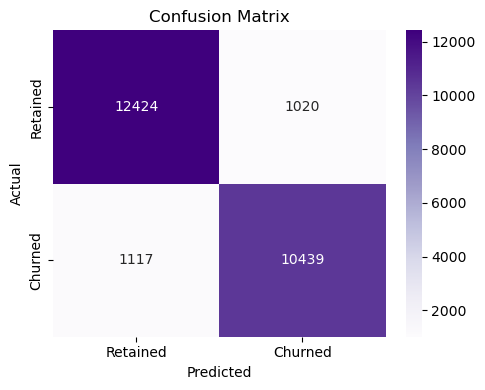

In [19]:
c_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(c_matrix, annot=True, fmt="d", cmap="Purples", xticklabels=["Retained", "Churned"], yticklabels=["Retained", "Churned"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()

In [20]:
auc = roc_auc_score(y_test, y_prob)
print("ROC-AUC:", round(auc, 4))

ROC-AUC: 0.977


Cross validation analysis

In [37]:
cv_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000))
])
 
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
 
# cross_val_score takes ONE scoring metric per call (unlike cross_validate,
# which accepts a list) -- simpler API, one call per metric.
accuracy_scores = cross_val_score(cv_pipeline, X_train_scaled, y_train, cv=cv, scoring="accuracy")
auc_scores = cross_val_score(cv_pipeline, X_train_scaled, y_train, cv=cv, scoring="roc_auc")
precision_scores = cross_val_score(cv_pipeline, X_train_scaled, y_train, cv=cv, scoring="precision")
recall_scores = cross_val_score(cv_pipeline, X_train_scaled, y_train, cv=cv, scoring="recall")
f1_scores = cross_val_score(cv_pipeline, X_train_scaled, y_train, cv=cv, scoring="f1")
 
cv_summary = pd.DataFrame({
    "accuracy": accuracy_scores,
    "roc_auc": auc_scores,
    "precision": precision_scores,
    "recall": recall_scores,
    "f1": f1_scores,
})
cv_summary.index = [f"fold_{i+1}" for i in range(5)]
 
print("\n--- 5-fold Stratified Cross-Validation (on training set) ---")
print(cv_summary.round(4))
print("\nMean +/- Std across folds:")
print((cv_summary.mean().round(4).astype(str) + " +/- " + cv_summary.std().round(4).astype(str)))


--- 5-fold Stratified Cross-Validation (on training set) ---
        accuracy  roc_auc  precision  recall      f1
fold_1    0.9137   0.9767     0.9058  0.9075  0.9067
fold_2    0.9125   0.9765     0.9039  0.9071  0.9055
fold_3    0.9147   0.9771     0.9094  0.9057  0.9075
fold_4    0.9132   0.9768     0.9089  0.9027  0.9058
fold_5    0.9111   0.9766     0.9044  0.9032  0.9038

Mean +/- Std across folds:
accuracy      0.913 +/- 0.0013
roc_auc      0.9767 +/- 0.0002
precision    0.9065 +/- 0.0025
recall       0.9052 +/- 0.0022
f1           0.9059 +/- 0.0014
dtype: object


Feature importance analysis

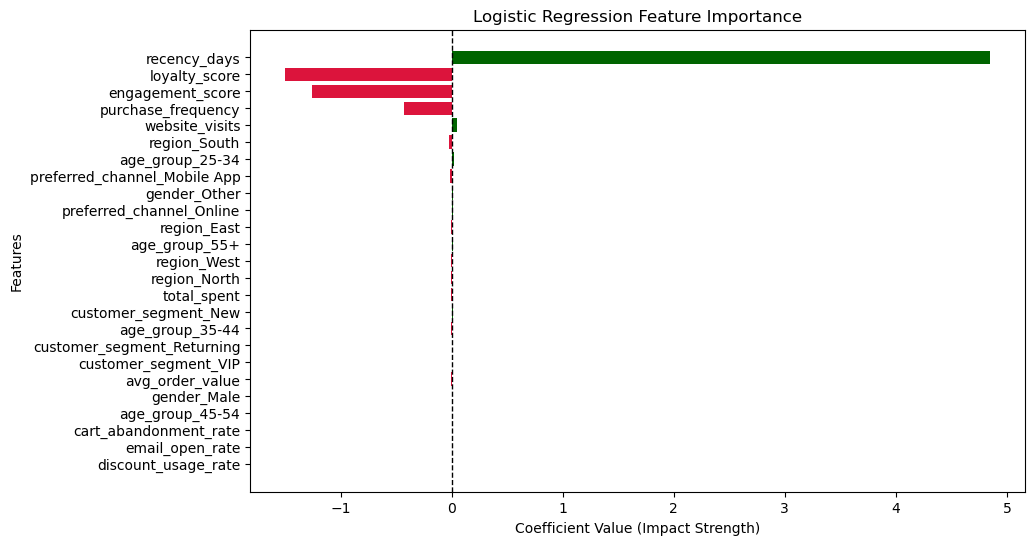

In [22]:


# Extract coefficients and match them with feature names
# 
feature_names = X_train.columns
coefficients = model.coef_[0]

# Create a DataFrame for easy sorting and plotting
importance_df = pd.DataFrame(
    {"Feature": feature_names, "Coefficient": coefficients}
)

# Sort by absolute value to see the strongest impacts first
importance_df["Abs_Coefficient"] = importance_df["Coefficient"].abs()
importance_df = importance_df.sort_values(
    by="Abs_Coefficient", ascending=False
).drop(columns="Abs_Coefficient")

#  Plot the feature importances
plt.figure(figsize=(10, 6))
colors = [
    "crimson" if c < 0 else "darkgreen" for c in importance_df["Coefficient"]
]
plt.barh(
    importance_df["Feature"], importance_df["Coefficient"], color=colors
)
plt.axvline(x=0, color="black", linestyle="--", linewidth=1)
plt.xlabel("Coefficient Value (Impact Strength)")
plt.ylabel("Features")
plt.title("Logistic Regression Feature Importance")
plt.gca().invert_yaxis()  # Put the strongest feature at the top
plt.show()